In [7]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

TARGET_SRATE = 22050
SAMPLE_COUNT = 2048
HOP_LENGTH = 512

paths = {
    "Song1": "/content/Achachak - First Movement.mp3",
    "Song2": "/content/Joint C Beat Laboratory - Margo.mp3",
    "Song3": "/content/Joint C Beat Laboratory - Nerves.mp3"
}

def load_audio(path, target_srate=TARGET_SRATE, normalize=True):
    y, srate = librosa.load(path, sr=None, mono=False)
    y_mono = librosa.to_mono(y) if y.ndim > 1 else y
    if srate != target_srate:
        y_resampled = librosa.resample(y_mono, orig_sr=srate, target_sr=target_srate)
    else:
        y_resampled = y_mono
    if normalize:
        peak = np.max(np.abs(y_resampled))
        if peak > 0:
            y_resampled = y_resampled / peak
    return y_resampled, target_srate

def comp_spectrogram(y, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH):
    y_stft = librosa.stft(y, n_fft=sample_count, hop_length=hop_length)
    y_mag = np.abs(y_stft)
    return librosa.amplitude_to_db(y_mag, ref=np.max)

In [8]:
def extract_average_spectral_features(y, sr=TARGET_SRATE, sample_count=SAMPLE_COUNT, 
                                      hop_length=HOP_LENGTH, max_freq=5000, include_std=False):
    stft_matrix = np.abs(librosa.stft(y, n_fft=sample_count, hop_length=hop_length))
    db_spec = librosa.amplitude_to_db(stft_matrix, ref=np.max)
    freq_resolution = sr / sample_count
    max_bin = min(int(max_freq / freq_resolution), db_spec.shape[0] - 1)
    db_spec_filtered = db_spec[:max_bin + 1, :]
    freq_axis = librosa.fft_frequencies(sr=sr, n_fft=sample_count)[:max_bin + 1]
    mean_spectrum = np.mean(db_spec_filtered, axis=1)
    mean_spectrum = (mean_spectrum - np.mean(mean_spectrum)) / (np.std(mean_spectrum) + 1e-8)
    if include_std:
        std_spectrum = np.std(db_spec_filtered, axis=1)
        std_spectrum = (std_spectrum - np.mean(std_spectrum)) / (np.std(std_spectrum) + 1e-8)
        feature_vector = np.concatenate([mean_spectrum, std_spectrum])
    else:
        feature_vector = mean_spectrum
    return feature_vector, freq_axis

def compute_similarity(feat_query, feat_target, metric="cosine"):
    u = np.asarray(feat_query, dtype=float)
    v = np.asarray(feat_target, dtype=float)
    if metric == "cosine":
        norm_u = np.linalg.norm(u)
        norm_v = np.linalg.norm(v)
        return float(np.dot(u, v) / (norm_u * norm_v)) if (norm_u > 0 and norm_v > 0) else 0.0
    elif metric == "correlation":
        u_c = u - np.mean(u)
        v_c = v - np.mean(v)
        norm_u = np.linalg.norm(u_c)
        norm_v = np.linalg.norm(v_c)
        return float(np.dot(u_c, v_c) / (norm_u * norm_v)) if (norm_u > 0 and norm_v > 0) else 0.0
    elif metric == "euclidean":
        dist = np.linalg.norm(u - v)
        return float(1.0 / (1.0 + dist))
    else:
        raise ValueError(f"Unknown metric '{metric}'")

In [9]:
class BaselineSpectralRecogniser:
    def __init__(self, sample_count=SAMPLE_COUNT, hop_length=HOP_LENGTH, 
                 max_freq=5000, metric="cosine", include_std=False):
        self.sample_count = sample_count
        self.hop_length = hop_length
        self.max_freq = max_freq
        self.metric = metric
        self.include_std = include_std
        self.database = {}
        self.freq_axis = None

    def index_song(self, name, y, sr=TARGET_SRATE):
        features, freq_axis = extract_average_spectral_features(
            y, sr=sr, sample_count=self.sample_count, hop_length=self.hop_length,
            max_freq=self.max_freq, include_std=self.include_std
        )
        self.database[name] = {"features": features, "raw_audio": y, "sr": sr}
        self.freq_axis = freq_axis

    def recognize(self, query_y, sr=TARGET_SRATE):
        if not self.database:
            raise ValueError("Database is empty! Call index_song() first.")
        query_feat, _ = extract_average_spectral_features(
            query_y, sr=sr, sample_count=self.sample_count, hop_length=self.hop_length,
            max_freq=self.max_freq, include_std=self.include_std
        )
        scores = {}
        for name, data in self.database.items():
            scores[name] = compute_similarity(query_feat, data["features"], metric=self.metric)
        ranked_results = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        return ranked_results[0][0], ranked_results[0][1], ranked_results

def identify_query_clip(query_audio, songs_dict, metric="cosine"):
    recogniser = BaselineSpectralRecogniser(metric=metric)
    for name, (y, sr) in songs_dict.items():
        recogniser.index_song(name, y, sr)
    best_song, best_score, _ = recogniser.recognize(query_audio)
    return best_song, best_score

def extract_query_clip(y, sr, start_sec, duration_sec, noise_snr_db=None, gain=1.0):
    start_sample = int(start_sec * sr)
    end_sample = start_sample + int(duration_sec * sr)
    clip = y[start_sample:min(end_sample, len(y))].copy() * gain
    if noise_snr_db is not None:
        signal_power = np.mean(clip ** 2)
        noise_power = signal_power / (10 ** (noise_snr_db / 10))
        noise = np.random.normal(0, np.sqrt(max(noise_power, 1e-12)), len(clip))
        clip = clip + noise
    return clip

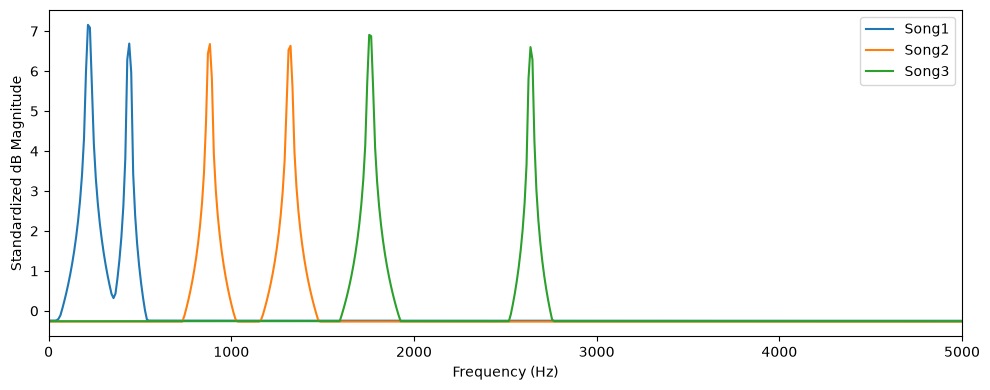

In [10]:
songs = {}
for name, path in paths.items():
    if os.path.exists(path):
        y, sr = load_audio(path)
        songs[name] = (y, sr)
    else:
        duration = 60.0
        t = np.linspace(0, duration, int(TARGET_SRATE * duration), endpoint=False)
        if name == "Song1":
            y = 0.6 * np.sin(2 * np.pi * 220 * t) + 0.3 * np.sin(2 * np.pi * 440 * t)
        elif name == "Song2":
            y = 0.4 * np.sin(2 * np.pi * 880 * t) + 0.4 * np.sin(2 * np.pi * 1320 * t)
        else:
            y = 0.5 * np.sin(2 * np.pi * 1760 * t) + 0.3 * np.sin(2 * np.pi * 2640 * t)
        y = y / np.max(np.abs(y))
        songs[name] = (y, TARGET_SRATE)

recogniser = BaselineSpectralRecogniser(metric="cosine")
for name, (y, sr) in songs.items():
    recogniser.index_song(name, y, sr)

plt.figure(figsize=(10, 4))
for name, data in recogniser.database.items():
    plt.plot(recogniser.freq_axis, data["features"], label=name)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Standardized dB Magnitude")
plt.xlim(0, 5000)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
test_configs = [
    ("Song1", 15.0, 10.0),
    ("Song2", 25.0, 10.0),
    ("Song3", 35.0, 10.0)
]

for true_song, start_sec, duration_sec in test_configs:
    y_full, sr = songs[true_song]
    query_clip = extract_query_clip(y_full, sr, start_sec, duration_sec)
    pred_song, best_score, leaderboard = recogniser.recognize(query_clip, sr=sr)
    print(f"Query: {true_song} [{start_sec}s-{start_sec+duration_sec}s] -> Predicted: {pred_song} (Score: {best_score:.4f})")
    for rank, (name, score) in enumerate(leaderboard, start=1):
        print(f"   {rank}. {name}: {score:.5f}")

Query: Song1 [15.0s-25.0s] -> Predicted: Song1 (Score: 1.0000)
   1. Song1: 0.99997
   2. Song2: -0.06375
   3. Song3: -0.06421
Query: Song2 [25.0s-35.0s] -> Predicted: Song2 (Score: 1.0000)
   1. Song2: 0.99998
   2. Song1: -0.06364
   3. Song3: -0.06886
Query: Song3 [35.0s-45.0s] -> Predicted: Song3 (Score: 1.0000)
   1. Song3: 0.99999
   2. Song1: -0.06383
   3. Song2: -0.06853


In [12]:
def sliding_window_recogniser(query_y, songs_dict, chunk_duration_sec=10.0, step_sec=2.0, sr=TARGET_SRATE):
    query_feat, _ = extract_average_spectral_features(query_y, sr=sr)
    results = {}
    best_offsets = {}
    chunk_samples = int(chunk_duration_sec * sr)
    step_samples = int(step_sec * sr)
    for name, (song_y, song_sr) in songs_dict.items():
        max_sim = -1.0
        best_time = 0.0
        for start in range(0, len(song_y) - chunk_samples, step_samples):
            chunk = song_y[start:start + chunk_samples]
            chunk_feat, _ = extract_average_spectral_features(chunk, sr=song_sr)
            sim = compute_similarity(query_feat, chunk_feat, metric="cosine")
            if sim > max_sim:
                max_sim = sim
                best_time = start / sr
        results[name] = max_sim
        best_offsets[name] = best_time
    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
    return sorted_results[0][0], sorted_results[0][1], best_offsets[sorted_results[0][0]], sorted_results

query_test = extract_query_clip(songs["Song2"][0], TARGET_SRATE, 40.0, 10.0)
best_s, best_sc, est_time, ranked = sliding_window_recogniser(query_test, songs, chunk_duration_sec=10.0)
print(f"Sliding Window Top Match: {best_s} | Score: {best_sc:.4f} | Estimated Offset: {est_time:.1f}s")
for rank, (s_name, s_score) in enumerate(ranked, 1):
    print(f"  {rank}. {s_name}: {s_score:.4f}")

Sliding Window Top Match: Song2 | Score: 1.0000 | Estimated Offset: 2.0s
  1. Song2: 1.0000
  2. Song1: -0.0616
  3. Song3: -0.0678
